In [2]:
#Nomes:Gaspar Tomas Bendzane

In [3]:
#Declaracao de Bibliotecas
import pandas as pd#To manipulate and analyze data
import numpy as np#To perform mathematical calculations
import openpyxl as ox#To enable Python to read and write files in Excel format (.xlsx)

In [4]:
#Reading the Excel database
df_Rendimento = pd.read_excel('Base_Rendimento.xlsx')

In [5]:
#Identification of missing values
df_Rendimento.isna().sum()#To calculate the number of missing values
(df_Rendimento.isna().mean()*100).round(1)#To calculate the percentage of missing values ​​per column

ID                      0.0
Anos de Escolaridade    2.4
Membros Activos         2.4
Rendimento Mensal       0.0
dtype: float64

In [6]:
#Data processing
#Identification of duplicate data
#We consider two or more identical data entries—sharing the same ID, years of schooling, active members, and income—to be duplicates.Mensal.
df_Rendimento.duplicated().sum()#Para calcular o numero de duplicados
df_Rendimento[df_Rendimento.duplicated]#Para identificar o duplicado

,ID,Anos de Escolaridade,Membros Activos,Rendimento Mensal
31,31,7.0,3.0,10800


In [7]:
#Remocao de dado duplicado
df_limpo = df_Rendimento.drop_duplicates(subset=['ID', 'Anos de Escolaridade', 'Membros Activos', 'Rendimento Mensal'])#Para eliminar duplicados
#Usamos o parametro SUBSET para remover duplicados considerando dados com mesmos, ID, Anos de Escolaridade, Membros Activos e Rendimento Mensal.
df_limpo.duplicated().sum()#Para calcular o numero de duplicados

np.int64(0)

In [8]:
#Identificacao de Valores nulos
df_limpo.isna().sum()#Para contar o numero total de valores em falta
(df_limpo.isna().mean()*100).round(1)#Para calcular a percentagem de valores em falta por coluna

ID                      0.0
Anos de Escolaridade    2.5
Membros Activos         2.5
Rendimento Mensal       0.0
dtype: float64

In [9]:
#Tratamento de Valores nulos
#Usaremos o metodo de remocao de dados nulos, pois, os dados que faltam representam uma porcentagem muito pequena e nao afetam o resultado final da nossa base de dado.
df_limpo = df_limpo.dropna(subset=['Anos de Escolaridade', 'Membros Activos'])#Para eliminar linhas com dados nulos.
print(df_limpo)

    ID  Anos de Escolaridade  Membros Activos  Rendimento Mensal
0    1                   5.0              2.0               8500
1    2                   7.0              3.0              10000
2    3                  10.0              3.0              14000
3    4                   4.0              2.0               7200
4    5                  12.0              4.0              19800
5    6                   6.0              2.0               9300
7    8                   3.0              1.0               6100
8    9                  11.0              4.0              18500
9   10                   9.0              3.0              15200
10  11                   5.0              2.0               8700
11  12                   7.0              3.0              11000
12  13                  10.0              4.0              17900
13  14                   4.0              2.0               7500
14  15                  13.0              4.0              21400
15  16                   

In [10]:
#Conversao de Tipo Primitivo
#As variaveis, Anos de Escolaridade e Membros de uma Familia, sao sempre numeros inteiros, por isso, convertemos de numero decimal para inteiros essas variaveis.
#O Rendimento Mensal nem sempre pode ser inteiro, portanto, convertemos para float (numero decimal).
df_limpo['Anos de Escolaridade']=df_limpo['Anos de Escolaridade'].astype(int)#Para converter de float para numero inteiro
df_limpo['Membros Activos']=df_limpo['Membros Activos'].astype(int)#Para converter de float para numero inteiro
df_limpo['Rendimento Mensal']=df_limpo['Rendimento Mensal'].astype(float)#Para converter de numero inteiro para float

In [11]:
#Resumo Estatistico da base Limpa
print(df_limpo.head(5))#Para mostrar as 5 primeiras linhas da tabela
print(df_limpo.info())#Para mostrar o resumo tecnico da tabela (Colunas, tipos de dados e valores em falta)
print(df_limpo.describe())#Para gerar resumo estatistico (media, minimo, maximo, desvio padrao)

   ID  Anos de Escolaridade  Membros Activos  Rendimento Mensal
0   1                     5                2             8500.0
1   2                     7                3            10000.0
2   3                    10                3            14000.0
3   4                     4                2             7200.0
4   5                    12                4            19800.0
<class 'pandas.DataFrame'>
Index: 38 entries, 0 to 40
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    38 non-null     int64  
 1   Anos de Escolaridade  38 non-null     int64  
 2   Membros Activos       38 non-null     int64  
 3   Rendimento Mensal     38 non-null     float64
dtypes: float64(1), int64(3)
memory usage: 1.5 KB
None
              ID  Anos de Escolaridade  Membros Activos  Rendimento Mensal
count  38.000000             38.000000        38.000000          38.000000
mean   20.763158   

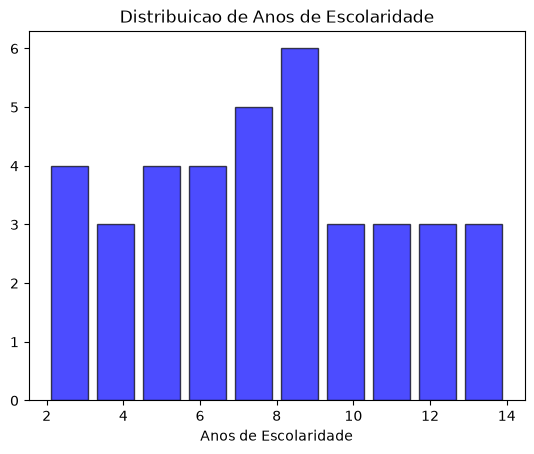

In [12]:
#Visualizacao
#Para produzir a distribuicao das variaveis, usamos o histograma, pois, podemos mostrar quantas observacoes caem em cada intervalo de valores.
import matplotlib.pyplot as plt#Biblioteca para criacao dos graficos
#Histograma de Anos de Escolaridade
plt.hist(df_limpo['Anos de Escolaridade'], bins=10, color='blue', edgecolor='black', alpha=0.7, rwidth=0.8)#Para criar o grafico
plt.xlabel('Anos de Escolaridade')#Valores de X (Anos de Escolaridade)
plt.title('Distribuicao de Anos de Escolaridade')#Titutlo do grafico
plt.show()

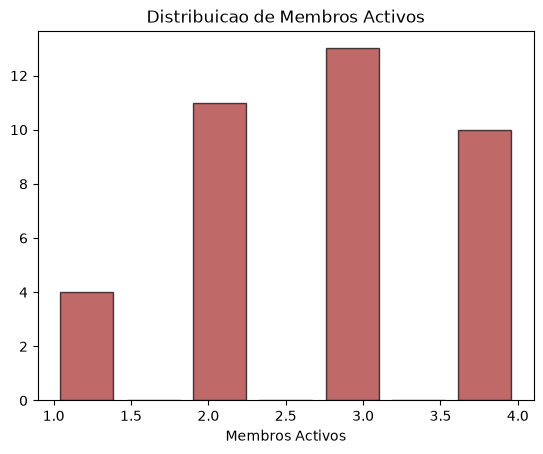

In [13]:
#Distribuicao dos Membros activos
plt.hist(df_limpo['Membros Activos'], bins=7, color='brown', alpha=0.7, edgecolor='black', rwidth=0.8)
plt.xlabel('Membros Activos')
plt.title('Distribuicao de Membros Activos')
plt.show()

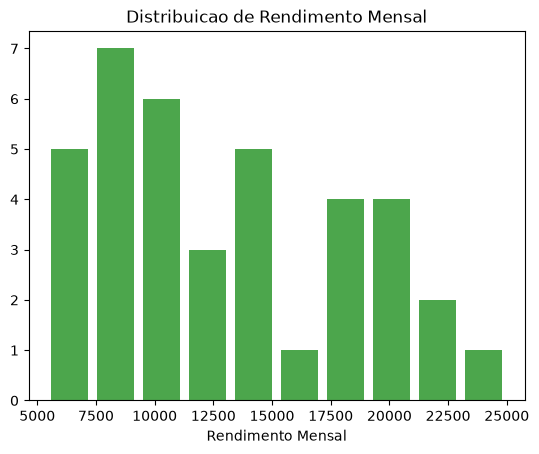

In [14]:
#Distribuicao do Rendimento Mensal 
plt.hist(df_limpo['Rendimento Mensal'], color='green', alpha=0.7, rwidth=0.8)#Para criar o Histograma
plt.xlabel('Rendimento Mensal')#Valores de X (Rendimento Mensal)
plt.title('Distribuicao de Rendimento Mensal')#Titulo do grafico
plt.show()

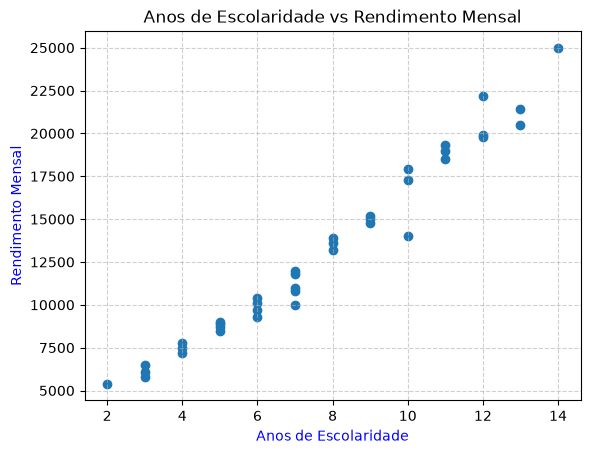

In [15]:
#Graficos de Dispersao
#Anos de Escolaridade vs Rendimento Mensal
plt.scatter(df_limpo['Anos de Escolaridade'], df_limpo['Rendimento Mensal'])#Para criar grafico de Dispersao.
plt.grid(True, linestyle='--', alpha=0.6)#Descricao do grafico
plt.xlabel('Anos de Escolaridade', color='blue')#Valores de X (Anos de Escolaridade)
plt.ylabel('Rendimento Mensal', color='blue')#Valores de Y (Rendimento Mensal)
plt.title('Anos de Escolaridade vs Rendimento Mensal')#Titulo do grafico
plt.show()

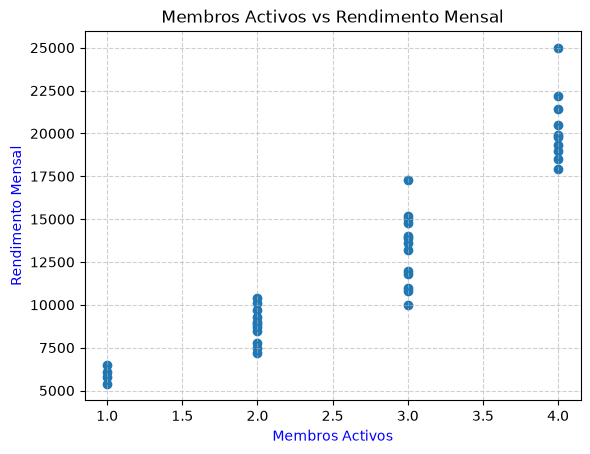

In [16]:
#Membros Activos vs Rendimento Mensal
plt.scatter(df_limpo['Membros Activos'], df_limpo['Rendimento Mensal'])#Para criar grafico de dispersao
plt.grid(True, linestyle='--', alpha=0.6)#Descricao do grafico
plt.xlabel('Membros Activos', color='blue')#Valores de x(Membros Activos)
plt.ylabel('Rendimento Mensal', color='blue')#Valores de Y(Rendimento Mensal)
plt.title('Membros Activos vs Rendimento Mensal')#Titulo do grafico
plt.show()

                      Anos de Escolaridade  Membros Activos  Rendimento Mensal
Anos de Escolaridade              1.000000         0.946817           0.984314
Membros Activos                   0.946817         1.000000           0.929642
Rendimento Mensal                 0.984314         0.929642           1.000000


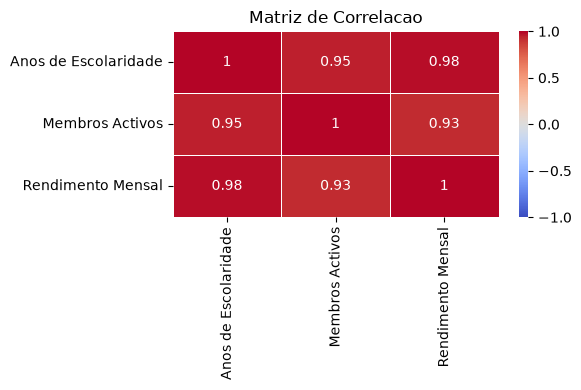

In [17]:
#Calculo e Apresentacao de Matriz de correlacao
import seaborn as sns #Para criar grafico de calor
matriz_correlacao = df_limpo[['Anos de Escolaridade', 'Membros Activos', 'Rendimento Mensal']].corr() #metodo de Pearson
print(matriz_correlacao)
plt.figure(figsize=(6, 4))#Tamanho do grafico
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)#Descricao do grafico
plt.title('Matriz de Correlacao')#Titulo do grafico
plt.tight_layout()#Ajustar grafico automaticamente
plt.show()

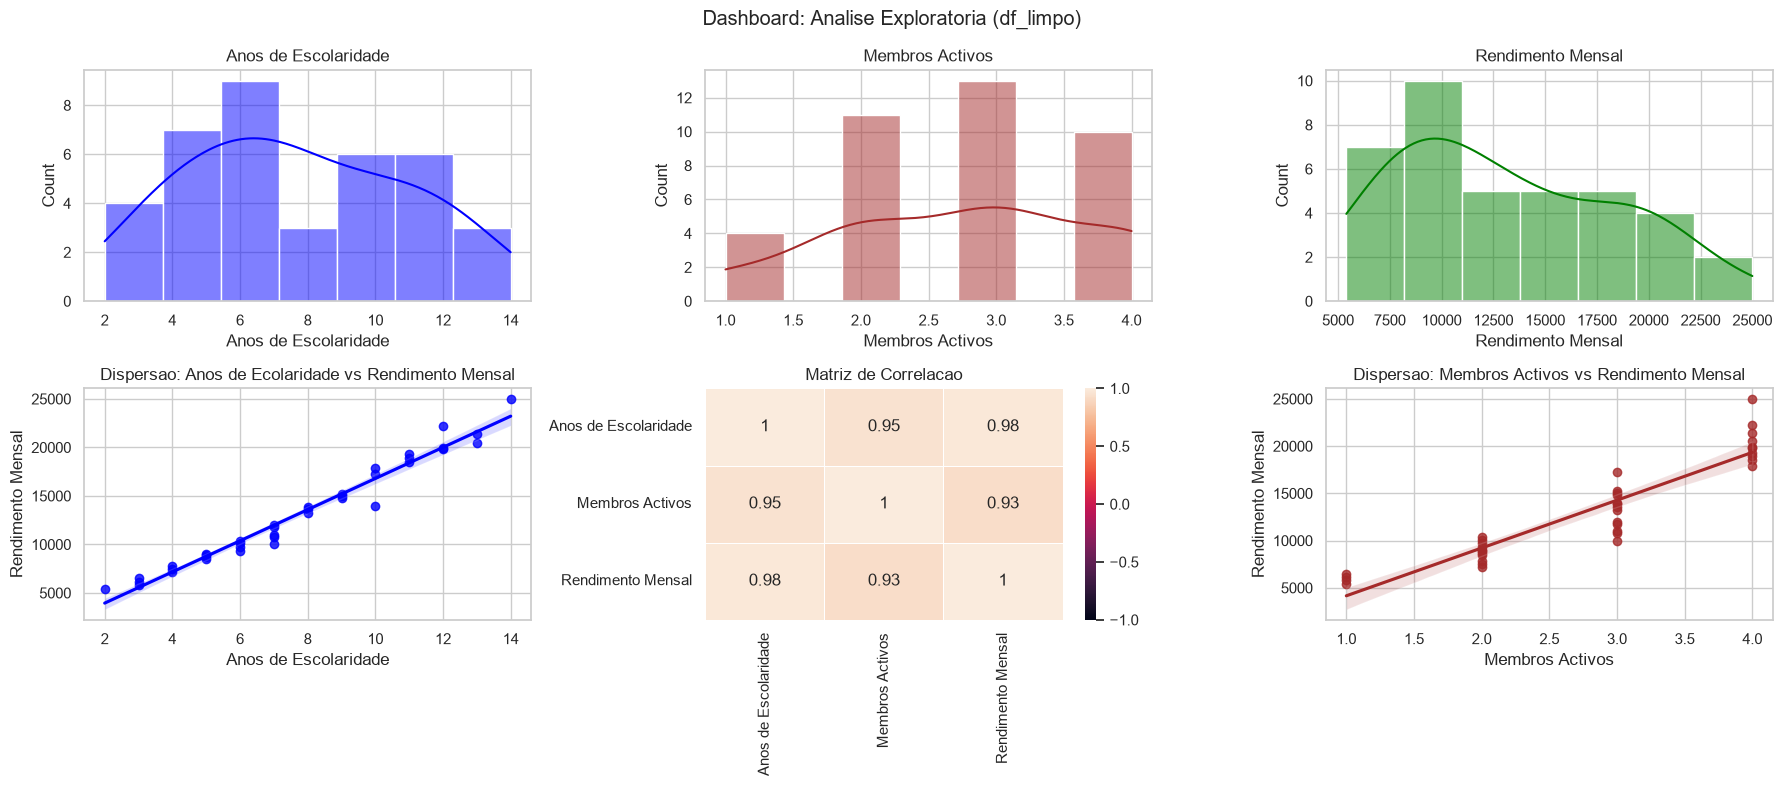

In [18]:
#Organizacao dos Graficos
#Organizacao do Dashboard
sns.set_theme(style='whitegrid')# Estilo do Dashboard
fig, axs = plt.subplots(2, 3, figsize=(18, 8)) #Tamanho Dashboard
fig.suptitle('Dashboard: Analise Exploratoria (df_limpo)') #Titulo do Dashboar
#Histograma: Anos de Escolaridade
sns.histplot(df_limpo['Anos de Escolaridade'], kde=True, ax=axs[0, 0], color='blue')
axs[0, 0].set_title('Anos de Escolaridade')
#Histograma: Membros Activos
sns.histplot(df_limpo['Membros Activos'], kde=True, ax=axs[0, 1], color='brown')
axs[0, 1].set_title('Membros Activos')
#Histograma: Rendimento Mensal
sns.histplot(df_limpo['Rendimento Mensal'], kde=True, ax=axs[0, 2], color='green')
axs[0, 2].set_title('Rendimento Mensal')
#Dispersao: Anos de Escolaridade vs Rendimento Mensal
sns.regplot(x='Anos de Escolaridade', y='Rendimento Mensal', data=df_limpo, ax=axs[1, 0], color='blue')
axs[1, 0].set_title('Dispersao: Anos de Ecolaridade vs Rendimento Mensal')
#Grafico de Calor
sns.heatmap(matriz_correlacao, annot=True, vmin=-1, vmax=1, linewidths=0.5, ax=axs[1, 1])
axs[1, 1].set_title('Matriz de Correlacao')
#Dispersao: Membros Activos vs Rendimento Mensal
sns.regplot(x='Membros Activos', y='Rendimento Mensal', data=df_limpo, ax=axs[1, 2], color='brown')
axs[1, 2].set_title('Dispersao: Membros Activos vs Rendimento Mensal')
plt.tight_layout()
plt.show()

In [19]:
#Declaração das bibliotecas para Machine Learning
from sklearn.model_selection import train_test_split #para dividir os dados em treino e teste
from sklearn.linear_model import LinearRegression #para criar o modelo de Regressão Linear
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score #para calcular o coeficiente de determinação R²

In [20]:
#Variáveis independentes (X)
X = df_limpo[['Anos de Escolaridade', 'Membros Activos']]

# Variável dependente (y)
y = df_limpo['Rendimento Mensal']

# Verificação
print("X:")
display(X.head())

print("\ny:")
display(y.head())

X:


,Anos de Escolaridade,Membros Activos
0,5,2
1,7,3
2,10,3
3,4,2
4,12,4



y:


0     8500.0
1    10000.0
2    14000.0
3     7200.0
4    19800.0
Name: Rendimento Mensal, dtype: float64

In [21]:
#Repartição dos dados do modelo (Treino) e (Teste)
#80% dos dados serão usados para treino e 20% para teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
#Repartição dos dados do modelo (Treino) e (Teste)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

In [23]:
#Criação, treinamento e previsões Modelo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

In [24]:
#Visualização dos Coeficientes do MRL e  calculo do R²
coeficientes = pd.DataFrame(modelo.coef_, X.columns, columns=['Coeficiente (Inclinação)'])
print(coeficientes)
print(f"\nIntercepto (Constante): {modelo.intercept_:.2f}")
r2 = modelo.score(X_teste, y_teste)
print(f"R² do modelo: {r2:.4f}")

                      Coeficiente (Inclinação)
Anos de Escolaridade               1713.097072
Membros Activos                    -153.678737

Intercepto (Constante): 325.60
R² do modelo: 0.9811


In [25]:
#Previsão do Rendimento Mensal
#Criação os dados do indivíduo para o qual queremos fazer a previsão e previsão do rendimento
novo_individuo = pd.DataFrame({'Anos de Escolaridade': [16], 'Membros Activos': [2]})
rendimento_previsto = modelo.predict(novo_individuo)
print(f"Rendimento Mensal previsto: {rendimento_previsto[0]:.2f} MT")

Rendimento Mensal previsto: 27427.79 MT
